# Homework 5: Decision Trees and Regression
**Name:** Vishnu Gamini  
**GitHub Username:** vishnugamini  
**USC ID:** 6350365744  
**Course:** DSCI 552

In [1]:
from pathlib import Path
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, hamming_loss, mean_squared_error, mean_absolute_error
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBRegressor
from threadpoolctl import threadpool_limits
from IPython.display import display

thread_limits = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
root = Path("..") if Path("../data/communities_and_crime").is_dir() else Path(".")
results_dir = root / "data" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
convergence_messages = []

## 1(a). Acute Inflammations data

The dataset has 120 records, six predictors, and two binary diagnosis labels.
Temperature is numeric; the five symptoms and both labels are encoded
no = 0 and yes = 1. Label powerset encoding preserves the joint outcome:
$c=2\,y_{bladder}+y_{nephritis}$, giving four possible classes.

In [2]:
acute_columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
                 "micturition_pain", "burning_urethra", "bladder_inflammation", "nephritis"]
acute = pd.read_csv(root / "data/acute_inflammations/diagnosis.data", sep="\t",
                    decimal=",", encoding="utf-16", names=acute_columns)
for column in acute_columns[1:]:
    acute[column] = acute[column].map({"no": 0, "yes": 1})
assert acute.shape == (120, 8) and not acute.isna().any().any()
Xa = acute.iloc[:, :6]
Ya = acute.iloc[:, 6:]
ya = 2*Ya["bladder_inflammation"] + Ya["nephritis"]
joint_names = ["Bladder=no; Nephritis=no", "Bladder=no; Nephritis=yes",
               "Bladder=yes; Nephritis=no", "Bladder=yes; Nephritis=yes"]
display(acute.head())
display(pd.DataFrame({"joint_class": range(4), "meaning": joint_names,
                       "records": ya.value_counts().reindex(range(4)).to_numpy()}))

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,bladder_inflammation,nephritis
0,35.500000,0,1,0,0,0,0,0
1,35.900000,0,0,1,1,1,1,0
2,35.900000,0,1,0,0,0,0,0
3,36.000000,0,0,1,1,1,1,0
4,36.000000,0,1,0,0,0,0,0


,joint_class,meaning,records
0,0,Bladder=no; Nephritis=no,30
1,1,Bladder=no; Nephritis=yes,31
2,2,Bladder=yes; Nephritis=no,40
3,3,Bladder=yes; Nephritis=yes,19


## 1(b). Decision tree fitted to all records

A Gini-impurity tree is fitted on the whole dataset, as requested. Each leaf
predicts both diagnosis labels through its joint class. The displayed accuracy
is training accuracy rather than a held-out estimate.

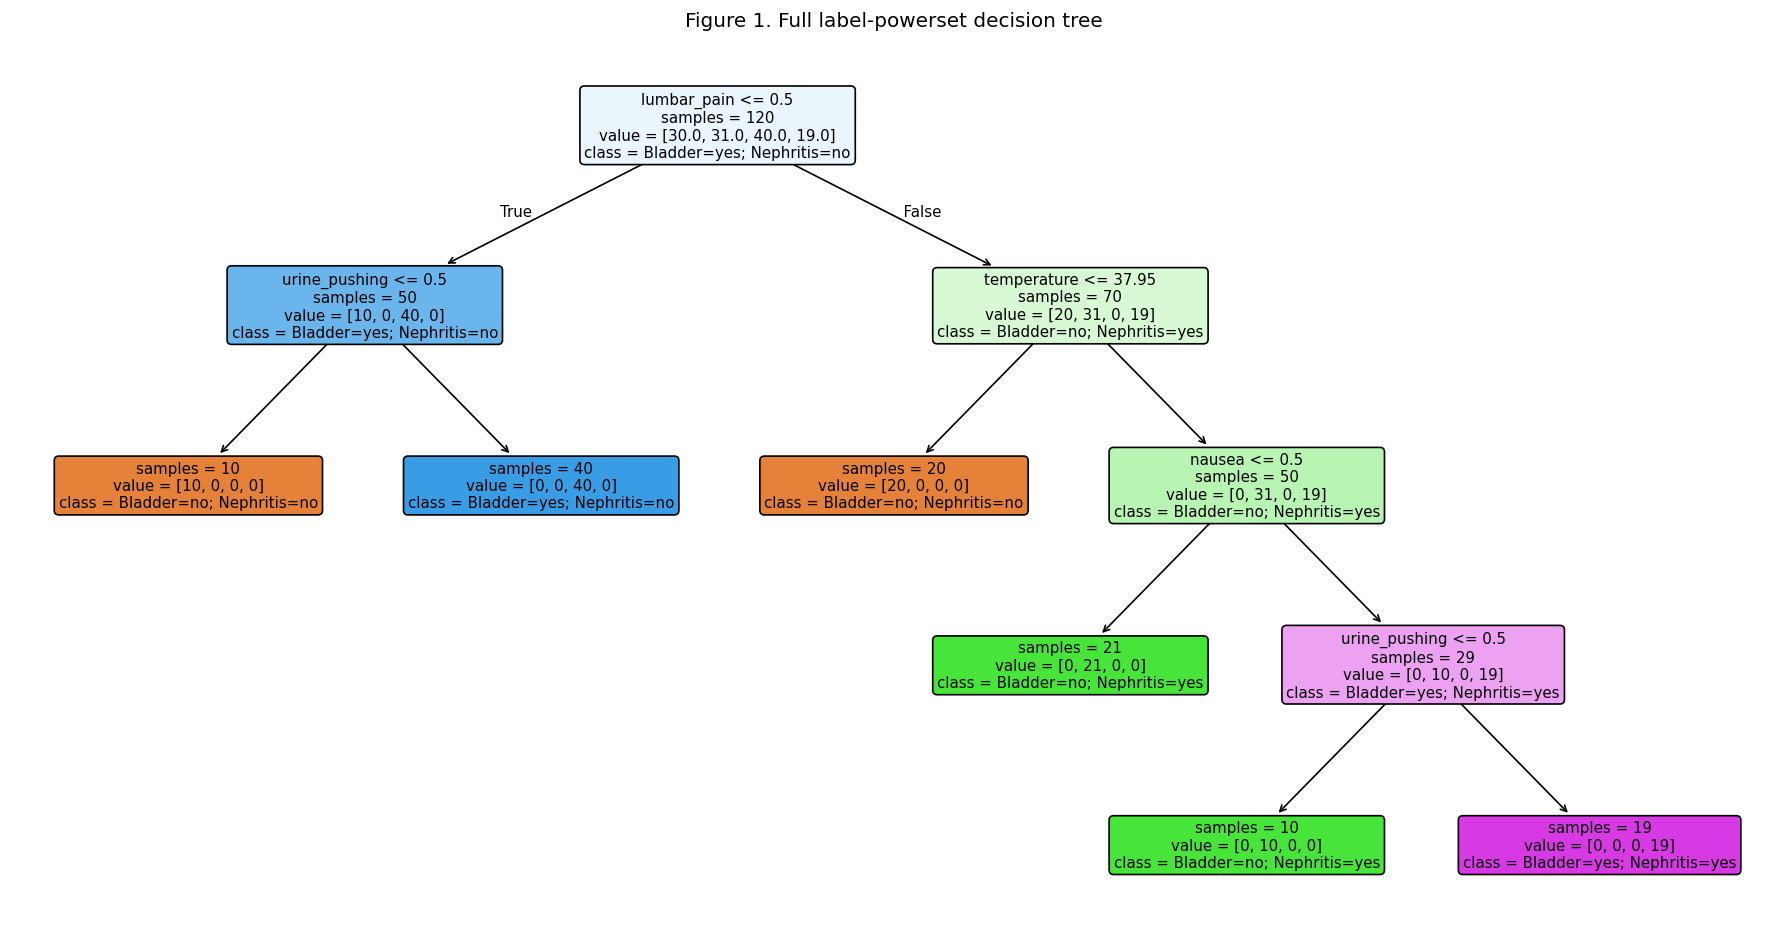

depth                     4.000000
leaves                    6.000000
training_joint_accuracy   1.000000
dtype: float64

In [3]:
full_tree = DecisionTreeClassifier(random_state=42).fit(Xa, ya)
fig, ax = plt.subplots(figsize=(15, 8))
plot_tree(full_tree, feature_names=Xa.columns.tolist(), class_names=joint_names,
          filled=True, rounded=True, impurity=False, proportion=False, fontsize=9, ax=ax)
ax.set_title("Figure 1. Full label-powerset decision tree")
fig.tight_layout()
plt.show()
display(pd.Series({"depth": full_tree.get_depth(), "leaves": full_tree.get_n_leaves(),
                   "training_joint_accuracy": full_tree.score(Xa, ya)}))

## 1(c). IF-THEN rules

Every root-to-leaf path becomes one rule. The conditions below simplify binary
splits to yes/no and retain numeric thresholds for temperature. Each rule gives
the two predicted diagnoses and the number of training records reaching its leaf.

In [4]:
def decision_rules(model):
    tree = model.tree_
    output = []
    def visit(node, conditions):
        left, right = tree.children_left[node], tree.children_right[node]
        if left == right:
            predicted = int(model.classes_[np.argmax(tree.value[node][0])])
            output.append({"leaf": node, "IF": " AND ".join(conditions) or "TRUE",
                           "THEN": joint_names[predicted], "joint_class": predicted,
                           "records": int(tree.n_node_samples[node])})
            return
        name = Xa.columns[tree.feature[node]]
        threshold = float(tree.threshold[node])
        if name != "temperature" and np.isclose(threshold, .5):
            low, high = f"{name} = no", f"{name} = yes"
        else:
            low, high = f"{name} <= {threshold:.2f}", f"{name} > {threshold:.2f}"
        visit(left, conditions + [low])
        visit(right, conditions + [high])
    visit(0, [])
    return pd.DataFrame(output)

full_rules = decision_rules(full_tree)
with pd.option_context("display.max_colwidth", None):
    display(full_rules[["IF", "THEN", "records"]])
full_rules.to_csv(results_dir / "full_tree_rules.csv", index=False)

,IF,THEN,records
0,lumbar_pain = no AND urine_pushing = no,Bladder=no; Nephritis=no,10
1,lumbar_pain = no AND urine_pushing = yes,Bladder=yes; Nephritis=no,40
2,lumbar_pain = yes AND temperature <= 37.95,Bladder=no; Nephritis=no,20
3,lumbar_pain = yes AND temperature > 37.95 AND nausea = no,Bladder=no; Nephritis=yes,21
4,lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no,Bladder=no; Nephritis=yes,10
5,lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes,Bladder=yes; Nephritis=yes,19


## 1(d). Cost-complexity pruning

Pruning minimizes $R(T)+\alpha|T|$, where $R(T)$ is the weighted leaf
impurity and $|T|$ is the number of leaves. Larger $\alpha$ favors smaller trees.
Five stratified folds score a fixed candidate grid, and the full-data pruning
path shows the available subtrees.

Two criteria make the accuracy/interpretability tradeoff explicit. The
one-standard-error rule chooses the largest tested $\alpha$ whose validation
accuracy is within one standard error of the best score. A more compact
alternative chooses the smallest tree attaining at least **80% mean validation
accuracy**. The 80% floor is an explicit interpretability tradeoff, not a claim
that it preserves the full tree's accuracy.

,alpha,leaves,depth,cv_accuracy,training_accuracy
One-SE choice,0.090000,6.000000,4.000000,0.991667,1.000000
Compact choice,0.100000,4.000000,2.000000,0.833333,0.841667


,alpha,leaf_impurity
0,0.000000,0.000000
1,0.098167,0.196333
2,0.133333,0.329667
3,0.182000,0.511667
4,0.222917,0.734583


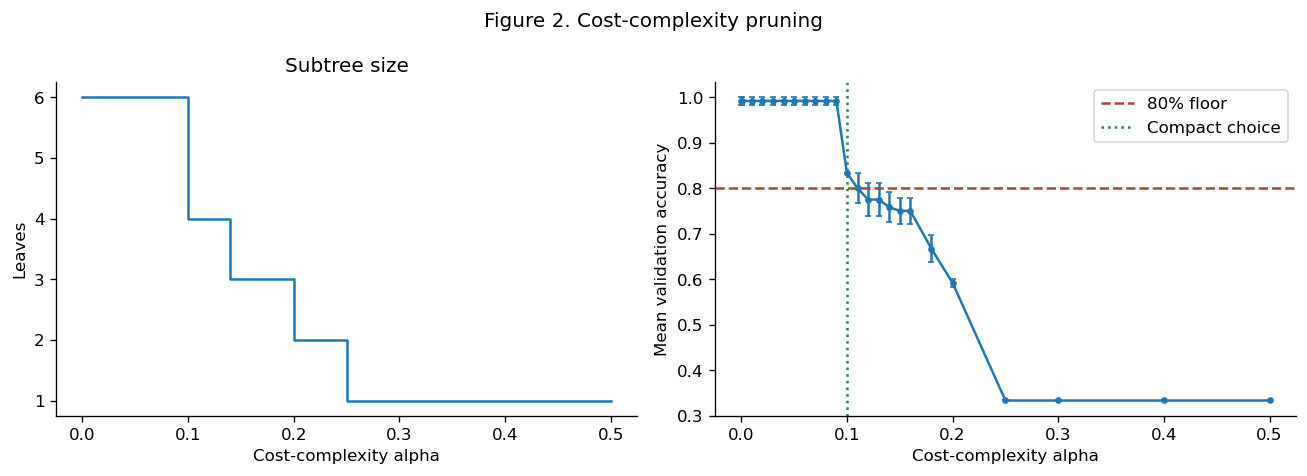

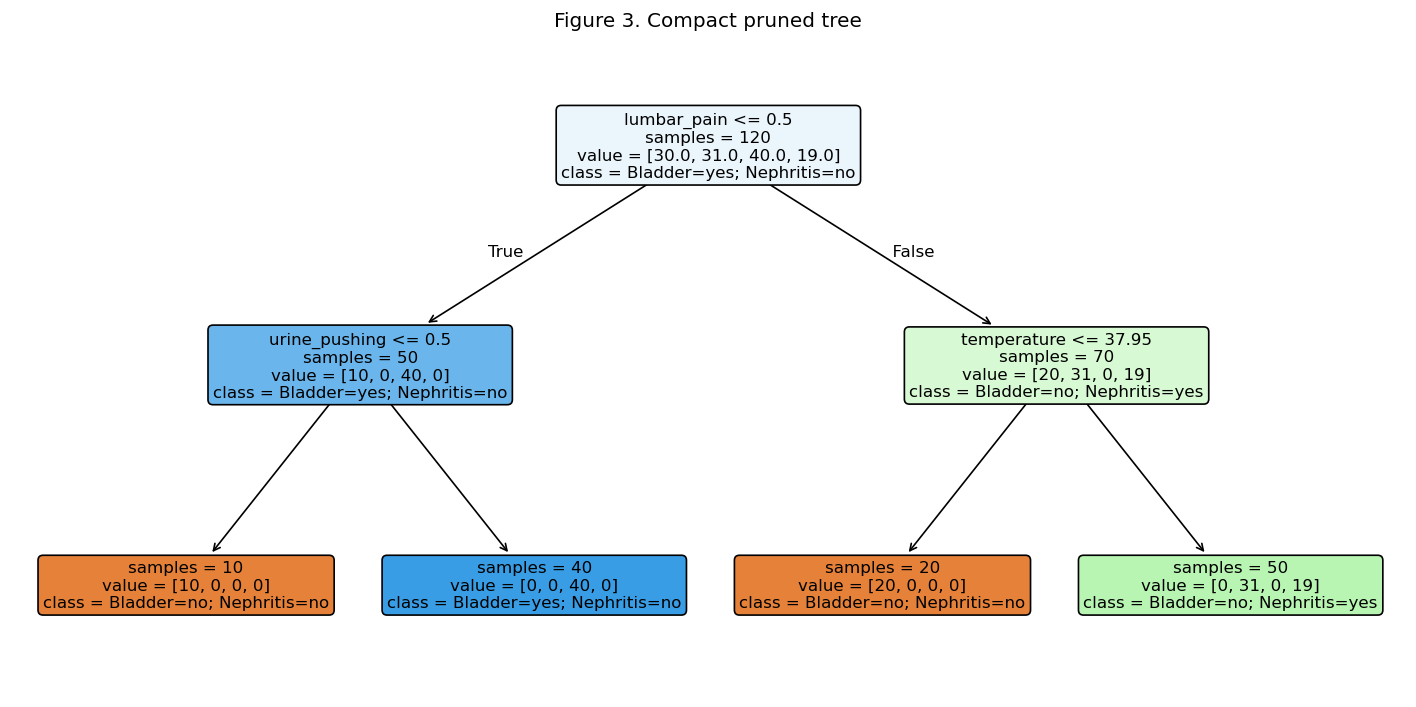

,IF,THEN,records
0,lumbar_pain = no AND urine_pushing = no,Bladder=no; Nephritis=no,10
1,lumbar_pain = no AND urine_pushing = yes,Bladder=yes; Nephritis=no,40
2,lumbar_pain = yes AND temperature <= 37.95,Bladder=no; Nephritis=no,20
3,lumbar_pain = yes AND temperature > 37.95,Bladder=no; Nephritis=yes,50


In [5]:
tree_folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(Xa, ya))
alpha_grid_tree = np.r_[0., .001, .01, np.arange(.02, .151, .01), .16, .18, .2, .25, .3, .4, .5]
tree_rows = []
for alpha in alpha_grid_tree:
    model = DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=42)
    scores = cross_val_score(model, Xa, ya, cv=tree_folds, scoring="accuracy")
    model.fit(Xa, ya)
    tree_rows.append({"alpha": alpha, "cv_accuracy": scores.mean(),
                      "cv_se": scores.std(ddof=1)/np.sqrt(len(scores)),
                      "leaves": model.get_n_leaves(), "depth": model.get_depth(),
                      "training_accuracy": model.score(Xa, ya),
                      **{f"fold_{i+1}": score for i, score in enumerate(scores)}})
tree_cv = pd.DataFrame(tree_rows)
best_tree_row = tree_cv.loc[tree_cv.cv_accuracy.idxmax()]
one_se_floor = best_tree_row.cv_accuracy - best_tree_row.cv_se
one_se_row = tree_cv.loc[tree_cv.cv_accuracy >= one_se_floor - 1e-12].sort_values("alpha").iloc[-1]
compact_row = tree_cv.loc[tree_cv.cv_accuracy >= .80 - 1e-12].sort_values(
    ["leaves", "cv_accuracy", "alpha"], ascending=[True, False, False]).iloc[0]
pruned_tree = DecisionTreeClassifier(ccp_alpha=float(compact_row.alpha), random_state=42).fit(Xa, ya)
pruned_rules = decision_rules(pruned_tree)
display(pd.DataFrame([one_se_row, compact_row], index=["One-SE choice", "Compact choice"])
        [["alpha", "leaves", "depth", "cv_accuracy", "training_accuracy"]])
path = full_tree.cost_complexity_pruning_path(Xa, ya)
path_table = pd.DataFrame({"alpha": path.ccp_alphas, "leaf_impurity": path.impurities})
display(path_table)
tree_cv.to_csv(results_dir / "tree_pruning_cv.csv", index=False)
path_table.to_csv(results_dir / "tree_pruning_path.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].step(tree_cv.alpha, tree_cv.leaves, where="post")
axes[0].set(xlabel="Cost-complexity alpha", ylabel="Leaves", title="Subtree size")
axes[1].errorbar(tree_cv.alpha, tree_cv.cv_accuracy, yerr=tree_cv.cv_se, marker=".", capsize=2)
axes[1].axhline(.80, color="#aa4433", linestyle="--", label="80% floor")
axes[1].axvline(compact_row.alpha, color="#228833", linestyle=":", label="Compact choice")
axes[1].set(xlabel="Cost-complexity alpha", ylabel="Mean validation accuracy")
axes[1].legend()
fig.suptitle("Figure 2. Cost-complexity pruning")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(pruned_tree, feature_names=Xa.columns.tolist(), class_names=joint_names,
          filled=True, rounded=True, impurity=False, fontsize=10, ax=ax)
ax.set_title("Figure 3. Compact pruned tree")
fig.tight_layout()
plt.show()
with pd.option_context("display.max_colwidth", None):
    display(pruned_rules[["IF", "THEN", "records"]])
pruned_rules.to_csv(results_dir / "pruned_tree_rules.csv", index=False)
acute_predictions = pd.DataFrame({"true_joint_class": ya,
    "full_tree_class": full_tree.predict(Xa), "pruned_tree_class": pruned_tree.predict(Xa)})
acute_predictions.to_csv(results_dir / "acute_tree_predictions.csv", index_label="row_index")

The one-standard-error choice retains **6 leaves**, with **99.17%** mean
validation accuracy. The compact alternative uses **alpha = 0.10**, reducing
the tree from depth 4 to depth 2 and from **6 rules to 4**. Its training joint
accuracy is **84.17%** and mean validation accuracy is **83.33%**.

This simplification has a substantial cost: the compact tree never predicts
the joint class in which both diagnoses are positive, misclassifying all 19
such training records. The six-rule tree is preferable when preserving that
outcome and predictive accuracy matters. Pruning therefore supplies a compact
rule set, but does not improve the accuracy-oriented choice on these data.

## 2(a). Communities and Crime: prescribed split

The target is `ViolentCrimesPerPop`. Source row order is preserved: rows
1–1495 are training observations and rows 1496–1994 are test observations.
The data description identifies `state`, `county`, `community`, `communityname`,
and `fold` as nonpredictive; these five columns are excluded, leaving 122
predictors. All regression models below use these 122 predictors, rather than
only the 11 chosen for exploratory plots.

In [6]:
crime_dir = root / "data/communities_and_crime"
column_names = re.findall(r"^@attribute\s+(\S+)\s+", (crime_dir / "communities.names").read_text(), re.M | re.I)
crime = pd.read_csv(crime_dir / "communities.data", names=column_names, na_values="?")
assert crime.shape == (1994, 128)
excluded = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
X = crime.drop(columns=excluded + [target]).astype(float)
y = crime[target].astype(float)
assert X.shape[1] == 122 and not y.isna().any()
X_train, X_test = X.iloc[:1495].copy(), X.iloc[1495:].copy()
y_train, y_test = y.iloc[:1495].copy(), y.iloc[1495:].copy()
assert len(X_train) == 1495 and len(X_test) == 499
regression_folds = list(KFold(5, shuffle=True, random_state=42).split(X_train))
display(pd.DataFrame({"rows": [len(X_train), len(X_test)], "predictors": [122, 122]},
                     index=["Train", "Test"]))

,rows,predictors
Train,1495,122
Test,499,122


## 2(b). Missing-value imputation

Each missing predictor is replaced by its training-column median. The same
medians transform the test observations. For model selection, the imputer
is refitted separately inside each training fold. The target is not imputed.

In [7]:
imputer = SimpleImputer(strategy="median")
Xi_train = pd.DataFrame(imputer.fit_transform(X_train), index=X_train.index, columns=X_train.columns)
Xi_test = pd.DataFrame(imputer.transform(X_test), index=X_test.index, columns=X_test.columns)
assert Xi_train.shape == X_train.shape and Xi_test.shape == X_test.shape
assert np.isfinite(Xi_train).all().all() and np.isfinite(Xi_test).all().all()
missing_table = pd.DataFrame({"train_missing": X_train.isna().sum(),
                              "test_missing": X_test.isna().sum(),
                              "training_median": imputer.statistics_})
display(missing_table.loc[missing_table.train_missing + missing_table.test_missing > 0])
missing_table.to_csv(results_dir / "missing_values_and_medians.csv", index_label="feature")

def preprocessing(standardize=False):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler() if standardize else "passthrough")])

def regression_pipeline(estimator, standardize=False):
    return Pipeline([("preprocess", preprocessing(standardize)), ("model", estimator)])

fold_cache = []
for fold_train, fold_valid in regression_folds:
    raw_prep = preprocessing(False).fit(X_train.iloc[fold_train])
    scaled_prep = preprocessing(True).fit(X_train.iloc[fold_train])
    fold_cache.append({"raw_train": raw_prep.transform(X_train.iloc[fold_train]),
                       "raw_valid": raw_prep.transform(X_train.iloc[fold_valid]),
                       "scaled_train": scaled_prep.transform(X_train.iloc[fold_train]),
                       "scaled_valid": scaled_prep.transform(X_train.iloc[fold_valid]),
                       "y_train": y_train.iloc[fold_train].to_numpy(),
                       "y_valid": y_train.iloc[fold_valid].to_numpy()})

,train_missing,test_missing,training_median
OtherPerCap,1,0,0.250000
LemasSwornFT,1256,419,0.020000
LemasSwFTPerPop,1256,419,0.180000
LemasSwFTFieldOps,1256,419,0.970000
LemasSwFTFieldPerPop,1256,419,0.210000
LemasTotalReq,1256,419,0.040000
LemasTotReqPerPop,1256,419,0.170000
PolicReqPerOffic,1256,419,0.300000
PolicPerPop,1256,419,0.180000
RacialMatchCommPol,1256,419,0.730000


## 2(c). Predictor correlation matrix

Pearson correlations below use the median-imputed training observations.
Strong positive and negative blocks indicate groups of related predictors;
correlation among predictors can make individual least-squares coefficients
unstable even when fitted predictions are useful.

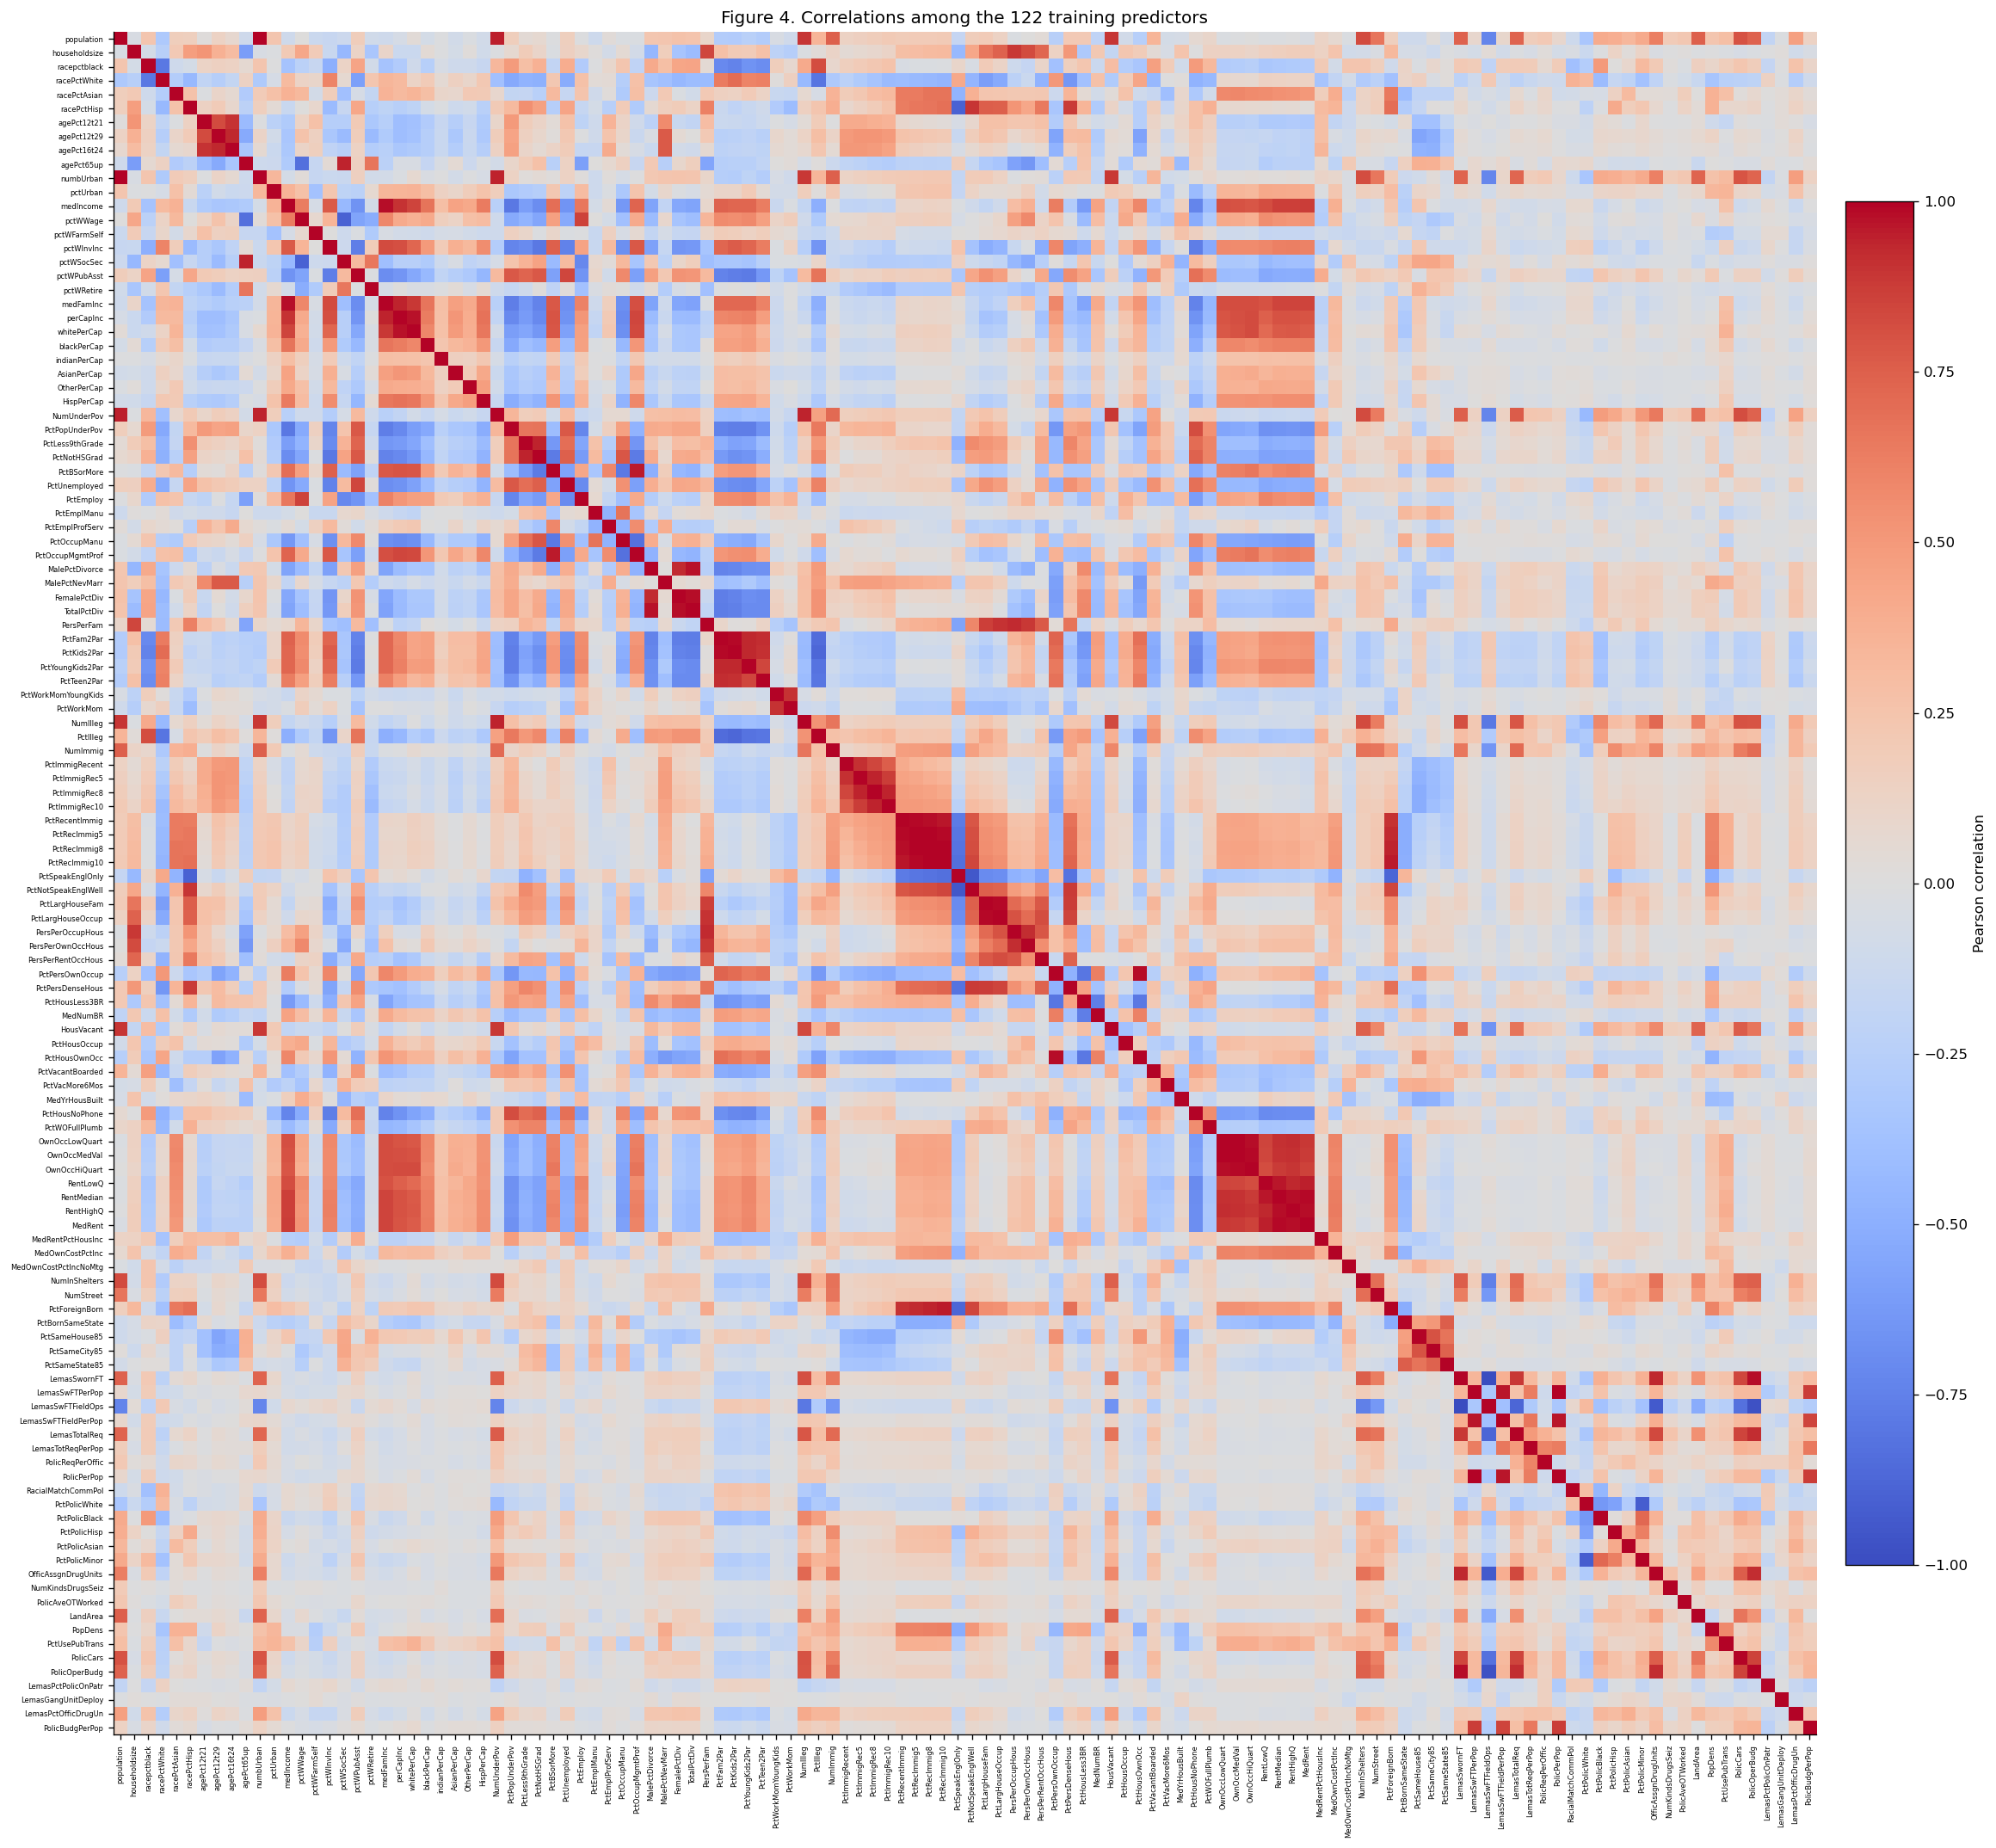

In [8]:
correlations = Xi_train.corr()
correlations.to_csv(results_dir / "predictor_correlations.csv")
fig, ax = plt.subplots(figsize=(20, 18))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm", interpolation="nearest")
ax.set_xticks(np.arange(len(X.columns)), X.columns, rotation=90, fontsize=5)
ax.set_yticks(np.arange(len(X.columns)), X.columns, fontsize=5)
fig.colorbar(image, ax=ax, fraction=.035, pad=.015, label="Pearson correlation")
ax.set_title("Figure 4. Correlations among the 122 training predictors")
fig.tight_layout()
plt.show()

## 2(d). Coefficient of variation

For each training predictor, $CV=s/\bar{x}$, where $s$ is the sample standard
deviation (`ddof=1`) after median imputation. A zero mean would make the ratio
undefined; no predictor here has a zero training mean. These CV values describe
the supplied normalized measurements and are not invariant to additive changes
in measurement origin.

In [9]:
cv_table = pd.DataFrame({"mean": Xi_train.mean(), "sample_std": Xi_train.std(ddof=1)})
cv_table["coefficient_of_variation"] = cv_table.sample_std / cv_table["mean"].replace(0, np.nan)
cv_table = cv_table.sort_values("coefficient_of_variation", ascending=False)
assert cv_table.coefficient_of_variation.notna().all()
with pd.option_context("display.max_rows", 122):
    display(cv_table)
cv_table.to_csv(results_dir / "coefficient_of_variation.csv", index_label="feature")

,mean,sample_std,coefficient_of_variation
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


## 2(e). The 11 predictors with highest CV

$\lfloor\sqrt{128}\rfloor=11$. The following scatterplots compare each
selected training predictor with the response, and the boxplots show their
marginal distributions. High CV often reflects a small mean and a long right
tail; it does not establish predictive relevance.

**Statistical significance cannot be determined from these plots alone.** A
visual association does not quantify sampling uncertainty, adjust for other
predictors, or establish a causal relationship. The plots can suggest patterns,
outliers, and nonlinear relationships for further analysis.

,mean,sample_std,coefficient_of_variation
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


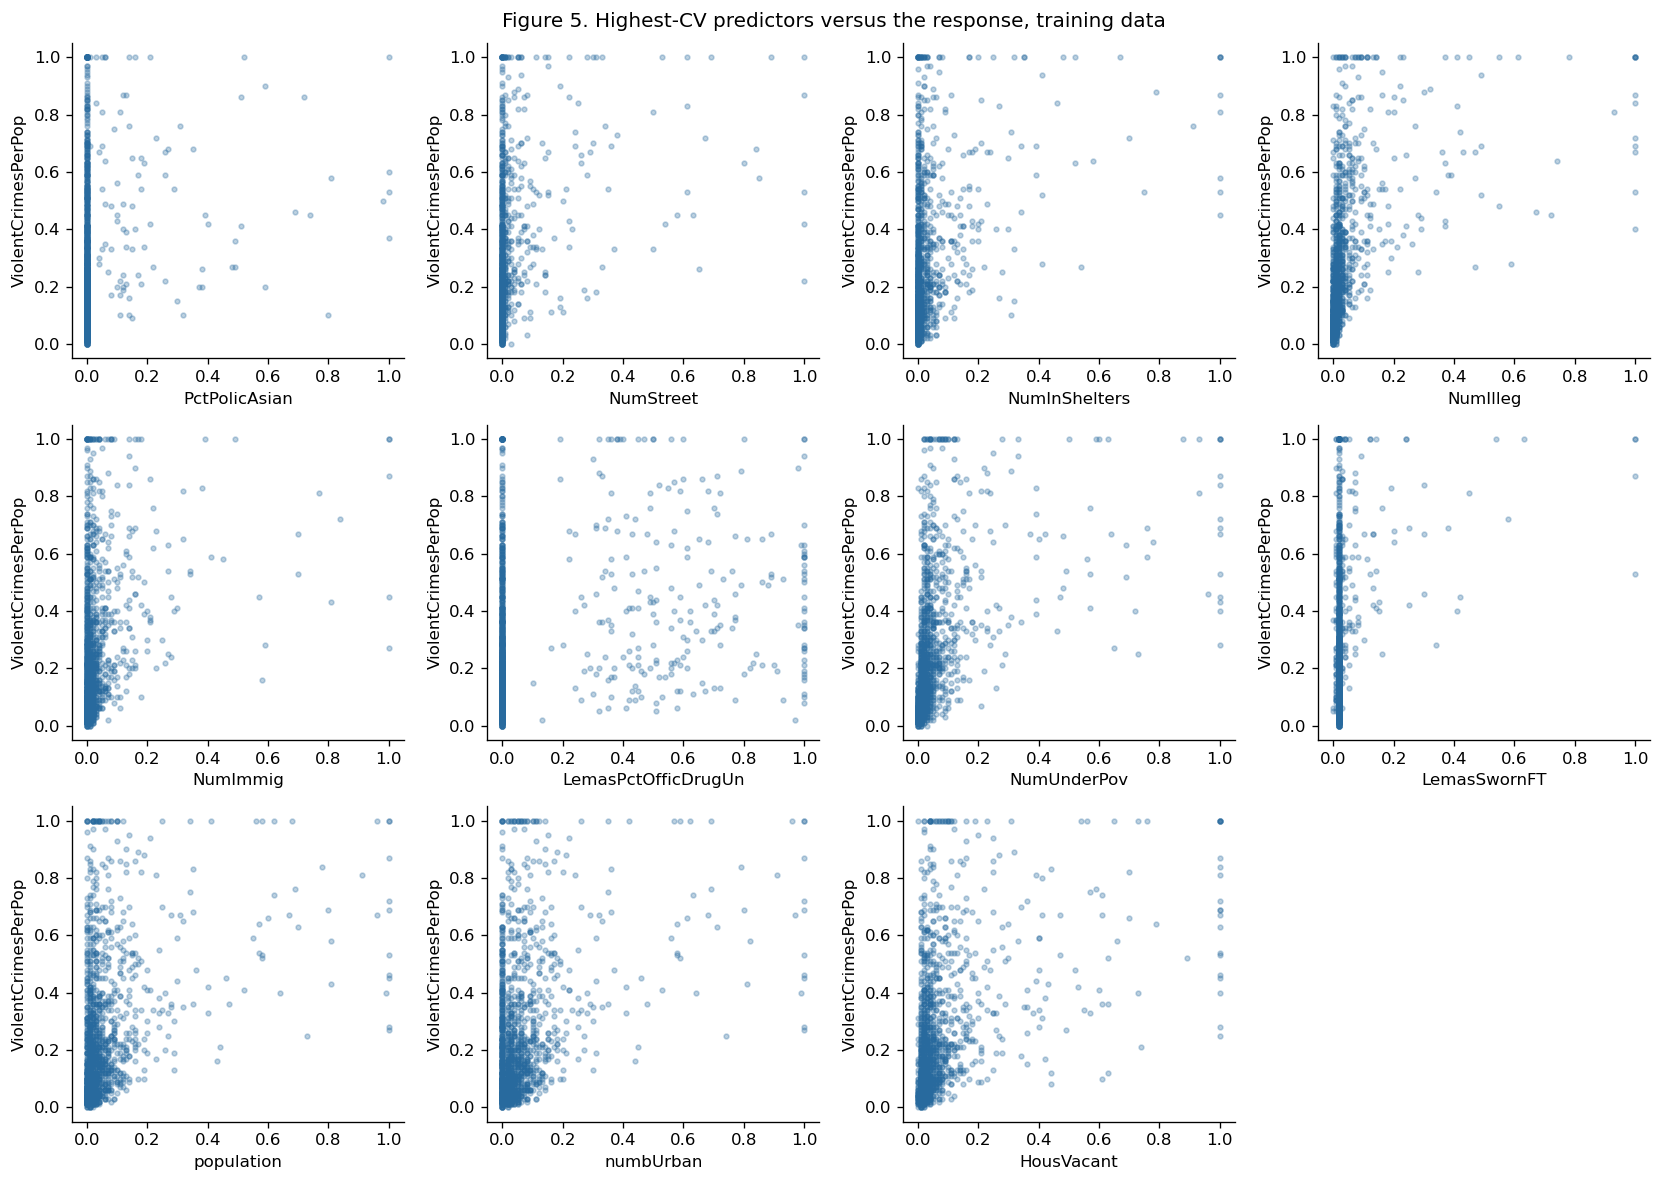

/var/folders/z8/_xxjmjrx1yb745vk2fmdd3800000gn/T/ipykernel_19085/3861399913.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([Xi_train[c] for c in top_features], labels=top_features,


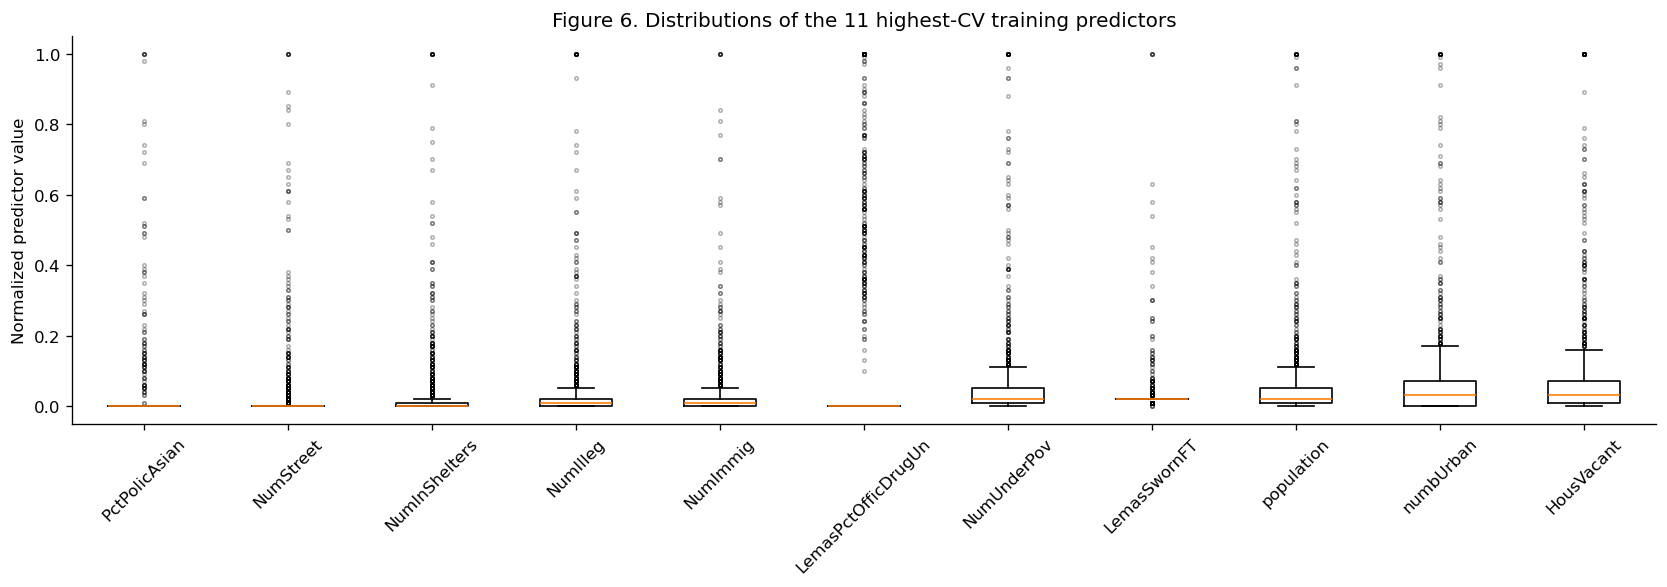

In [10]:
top_features = cv_table.index[:int(np.floor(np.sqrt(128)))].tolist()
display(cv_table.loc[top_features])
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for column, ax in zip(top_features, axes.flat):
    ax.scatter(Xi_train[column], y_train, s=8, alpha=.3, color="#286a9e")
    ax.set(xlabel=column, ylabel=target)
axes.flat[-1].set_visible(False)
fig.suptitle("Figure 5. Highest-CV predictors versus the response, training data")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot([Xi_train[c] for c in top_features], labels=top_features,
           flierprops={"markersize": 2, "alpha": .3})
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Normalized predictor value")
ax.set_title("Figure 6. Distributions of the 11 highest-CV training predictors")
fig.tight_layout()
plt.show()

## 2(f). Least-squares regression

The test MSE is **0.017966**, with RMSE **0.134038**.

All 122 predictors and an intercept are included. Test error is reported as
mean squared error (MSE); RMSE and MAE are also shown on the target's normalized
scale. Predictions are evaluated directly without clipping.

In [11]:
models = {}
regression_results = []
test_predictions = pd.DataFrame({"source_row": np.arange(1496, 1995),
                                 "actual": y_test.to_numpy()})
def report_regression(name, model, cv_mse=np.nan):
    predicted_train, predicted_test = model.predict(X_train), model.predict(X_test)
    row = {"model": name, "cv_mse": cv_mse,
           "train_mse": mean_squared_error(y_train, predicted_train),
           "test_mse": mean_squared_error(y_test, predicted_test),
           "test_rmse": np.sqrt(mean_squared_error(y_test, predicted_test)),
           "test_mae": mean_absolute_error(y_test, predicted_test)}
    regression_results.append(row)
    test_predictions[name] = predicted_test
    models[name] = model
    display(pd.DataFrame([row]).set_index("model"))

ols = regression_pipeline(LinearRegression()).fit(X_train, y_train)
ols_cv = -cross_val_score(regression_pipeline(LinearRegression()), X_train, y_train,
                           cv=regression_folds, scoring="neg_mean_squared_error")
report_regression("OLS", ols, ols_cv.mean())

,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
OLS,0.020785,0.016292,0.017966,0.134038,0.096265


## 2(g). Ridge regression

The selected penalty is **lambda = 125.892541**. Test MSE is **0.017372**,
slightly lower than least squares.

Predictors are median-imputed and standardized inside each fold. Five-fold
cross-validation searches 81 penalties from $10^{-4}$ to $10^4$, evenly spaced
on a logarithmic scale, minimizing mean validation MSE. The fitted objective is
$\mathrm{RSS}+\lambda\sum_j\beta_j^2$; the intercept is not penalized.

In [12]:
ridge_grid = np.logspace(-4, 4, 81)
ridge_search = GridSearchCV(regression_pipeline(Ridge(), True),
    {"model__alpha": ridge_grid}, scoring="neg_mean_squared_error", cv=regression_folds,
    n_jobs=1, error_score="raise").fit(X_train, y_train)
ridge = ridge_search.best_estimator_
ridge_lambda = float(ridge_search.best_params_["model__alpha"])
ridge_cv = pd.DataFrame({"lambda": ridge_search.cv_results_["param_model__alpha"].astype(float),
                         "cv_mse": -ridge_search.cv_results_["mean_test_score"],
                         **{f"fold_{i+1}": -ridge_search.cv_results_[f"split{i}_test_score"] for i in range(5)}})
ridge_cv.to_csv(results_dir / "ridge_cv.csv", index=False)
display(pd.Series({"selected_lambda": ridge_lambda}))
report_regression("Ridge standardized", ridge, -ridge_search.best_score_)

selected_lambda   125.892541
dtype: float64

,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
Ridge standardized,0.019738,0.017234,0.017372,0.131805,0.094257


## 2(h). LASSO with original and standardized predictors

With the original normalized predictors, **lambda = 0.000112202** selects
**73 variables**, giving test MSE **0.017642**. With standardization,
**lambda = 0.000630957** selects **76 variables**, giving test MSE **0.017722**.
The original version performs slightly better here. Equal 0–1 ranges do not
imply equal standard deviations, so additional standardization changes the
effective penalty on each original coefficient; it need not improve test error.

Both searches use the same five folds and 101 penalties from $10^{-5}$ to 1.
The LASSO objective is $\mathrm{RSS}/(2n)+\lambda\sum_j|\beta_j|$, so its
numeric penalty is not directly comparable to ridge's penalty. For the original
version, predictors retain their supplied 0–1 normalization after imputation.
The standardized version additionally uses each training fold's mean and
standard deviation.

Within each fold, a centered warm-start regularization path evaluates all
penalties. Validation observations never contribute to imputation, centering,
or scaling. The minimum mean validation MSE determines each penalty. Coefficients
with absolute value greater than $10^{-8}$ are listed as selected variables.

In [13]:
lasso_lambdas = np.logspace(0, -5, 101)
lasso_tables = {}
selected_lasso = {}
for standardized, label in [(False, "LASSO original"), (True, "LASSO standardized")]:
    fold_errors = []
    for fold in fold_cache:
        prefix = "scaled" if standardized else "raw"
        Xt, Xv = fold[prefix + "_train"], fold[prefix + "_valid"]
        yt, yv = fold["y_train"], fold["y_valid"]
        xm, ym = Xt.mean(axis=0), yt.mean()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            path_alphas, path_coefs, dual_gaps, iterations = lasso_path(
                np.asfortranarray(Xt-xm), yt-ym, alphas=lasso_lambdas,
                max_iter=100000, tol=1e-7, return_n_iter=True)
        convergence_messages.extend(str(w.message) for w in caught
                                    if issubclass(w.category, ConvergenceWarning))
        assert np.allclose(path_alphas, lasso_lambdas)
        predictions = (Xv-xm) @ path_coefs + ym
        fold_errors.append(np.mean((yv[:, None]-predictions)**2, axis=0))
    errors = np.array(fold_errors)
    table = pd.DataFrame({"lambda": lasso_lambdas, "cv_mse": errors.mean(axis=0),
                          **{f"fold_{i+1}": errors[i] for i in range(5)}})
    best_index = int(np.argmin(table.cv_mse.to_numpy()))
    penalty = float(table.iloc[best_index]["lambda"])
    model = regression_pipeline(Lasso(alpha=penalty, max_iter=100000, tol=1e-7), standardized)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)
    convergence_messages.extend(str(w.message) for w in caught
                                if issubclass(w.category, ConvergenceWarning))
    coef = model.named_steps["model"].coef_
    selected = pd.DataFrame({"feature": X.columns, "coefficient": coef})
    selected = selected.loc[np.abs(selected.coefficient) > 1e-8].reset_index(drop=True)
    selected_lasso[label] = selected
    lasso_tables[label] = table
    suffix = "standardized" if standardized else "original"
    table.to_csv(results_dir / f"lasso_{suffix}_cv.csv", index=False)
    selected.to_csv(results_dir / f"lasso_{suffix}_selected.csv", index=False)
    display(pd.Series({"model": label, "selected_lambda": penalty,
                       "selected_predictors": len(selected),
                       "coordinate_descent_iterations": int(model.named_steps["model"].n_iter_)}))
    with pd.option_context("display.max_rows", 122):
        display(selected)
    report_regression(label, model, float(table.iloc[best_index].cv_mse))

model                            LASSO original
selected_lambda                        0.000112
selected_predictors                          73
coordinate_descent_iterations               554
dtype: object

,feature,coefficient
0,racepctblack,0.268119
1,racePctAsian,-0.015724
2,agePct12t21,0.068354
3,agePct12t29,-0.271445
4,pctUrban,0.040896
5,pctWWage,-0.085282
6,pctWFarmSelf,0.027157
7,pctWInvInc,-0.102075
8,pctWSocSec,0.052437
9,pctWPubAsst,0.040670


,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
LASSO original,0.019515,0.016936,0.017642,0.132821,0.094577


model                            LASSO standardized
selected_lambda                            0.000631
selected_predictors                              76
coordinate_descent_iterations                   546
dtype: object

,feature,coefficient
0,racepctblack,0.068005
1,racePctAsian,-0.001863
2,agePct12t21,0.012486
3,agePct12t29,-0.043304
4,pctUrban,0.017131
5,pctWWage,-0.014239
6,pctWFarmSelf,0.004848
7,pctWInvInc,-0.022144
8,pctWSocSec,0.010404
9,pctWPubAsst,0.007915


,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
LASSO standardized,0.019661,0.016903,0.017722,0.133123,0.094774


## 2(i). Principal component regression

Cross-validation selects **M = 60** principal components. Test MSE is
**0.018350**, higher than the selected ridge and LASSO models. Components
explain predictor variation, which need not be the variation most useful for
predicting the response.

Median imputation and standardization are fitted inside each fold, followed by
PCA. All $M\in\{1,\ldots,122\}$ are evaluated. Because the training component
scores are orthogonal, their regression coefficients can be computed once;
cumulative predictions then score every truncation. The full-training model
uses the selected $M$ and is evaluated on the unchanged test set.

In [14]:
component_grid = np.arange(1, X.shape[1]+1)
pcr_errors = []
for fold in fold_cache:
    Xt, Xv = fold["scaled_train"], fold["scaled_valid"]
    yt, yv = fold["y_train"], fold["y_valid"]
    fold_pca = PCA(n_components=X.shape[1], svd_solver="full").fit(Xt)
    Tt, Tv = fold_pca.transform(Xt), fold_pca.transform(Xv)
    denominator = np.sum(Tt**2, axis=0)
    weights = np.divide(Tt.T @ (yt-yt.mean()), denominator,
                        out=np.zeros(X.shape[1]), where=denominator > 1e-20)
    all_predictions = yt.mean() + np.cumsum(Tv*weights, axis=1)
    pcr_errors.append(np.mean((yv[:, None]-all_predictions)**2, axis=0))
pcr_errors = np.array(pcr_errors)
pcr_cv = pd.DataFrame({"M": component_grid, "cv_mse": pcr_errors.mean(axis=0),
                       **{f"fold_{i+1}": pcr_errors[i] for i in range(5)}})
best_M = int(pcr_cv.loc[pcr_cv.cv_mse.idxmin(), "M"])
pcr = Pipeline([("preprocess", preprocessing(True)),
                ("pca", PCA(n_components=best_M, svd_solver="full")),
                ("model", LinearRegression())]).fit(X_train, y_train)
pcr_cv.to_csv(results_dir / "pcr_cv.csv", index=False)
display(pd.Series({"selected_M": best_M,
                   "training_explained_variance_ratio": pcr.named_steps["pca"].explained_variance_ratio_.sum()}))
report_regression("PCR standardized", pcr, float(pcr_cv.cv_mse.min()))

selected_M                          60.000000
training_explained_variance_ratio    0.980634
dtype: float64

,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
PCR standardized,0.020210,0.017939,0.018350,0.135460,0.097174


## 2(j). L1-regularized gradient-boosted trees

Cross-validation selects **alpha = 0.1**, giving test MSE **0.016429**.

XGBoost is fitted with `booster="gbtree"`, squared-error loss, 500 trees,
depth 3, learning rate 0.05, and L2 penalty 1. Five-fold cross-validation selects
`reg_alpha` from $\{0,10^{-4},10^{-3},10^{-2},0.1,0.3,1,3,10,30,100\}$.
Imputation is fitted within folds and no early stopping uses test data.

For XGBoost's tree booster, $\alpha$ penalizes **leaf weights**:
$\Omega=\gamma T+\tfrac12\lambda\sum_jw_j^2+\alpha\sum_j|w_j|$.
Its standard leaves are constants; this implementation does not fit a separate
LASSO regression at each internal node. This is the L1-regularized tree booster
offered by the package recommended in the assignment.

In [15]:
xgb_alpha_grid = [0., 1e-4, 1e-3, .01, .1, .3, 1., 3., 10., 30., 100.]
xgb_base = XGBRegressor(booster="gbtree", objective="reg:squarederror",
    n_estimators=500, max_depth=3, learning_rate=.05, reg_lambda=1.,
    subsample=1., colsample_bytree=1., tree_method="hist", device="cpu",
    n_jobs=1, random_state=42)
xgb_search = GridSearchCV(regression_pipeline(xgb_base), {"model__reg_alpha": xgb_alpha_grid},
    scoring="neg_mean_squared_error", cv=regression_folds, n_jobs=1, error_score="raise").fit(X_train, y_train)
xgb = xgb_search.best_estimator_
xgb_alpha = float(xgb_search.best_params_["model__reg_alpha"])
xgb_cv = pd.DataFrame({"alpha": xgb_search.cv_results_["param_model__reg_alpha"].astype(float),
                       "cv_mse": -xgb_search.cv_results_["mean_test_score"],
                       **{f"fold_{i+1}": -xgb_search.cv_results_[f"split{i}_test_score"] for i in range(5)}})
xgb_cv.to_csv(results_dir / "xgboost_alpha_cv.csv", index=False)
xgb.named_steps["model"].save_model(results_dir / "xgboost_model.json")
display(xgb_cv)
display(pd.Series({"selected_alpha": xgb_alpha}))
report_regression("XGBoost L1 trees", xgb, -xgb_search.best_score_)

,alpha,cv_mse,fold_1,fold_2,fold_3,fold_4,fold_5
0,0.000000,0.020463,0.019810,0.019923,0.021516,0.018452,0.022615
1,0.000100,0.020358,0.019848,0.019901,0.021632,0.018030,0.022380
2,0.001000,0.020282,0.019791,0.019791,0.021171,0.018439,0.022215
3,0.010000,0.020185,0.019577,0.019500,0.021367,0.018125,0.022357
4,0.100000,0.019942,0.019622,0.018875,0.020770,0.018410,0.022036
5,0.300000,0.020212,0.019111,0.019684,0.021432,0.018145,0.022686
6,1.000000,0.020359,0.019544,0.019770,0.021351,0.018339,0.022791
7,3.000000,0.020288,0.019527,0.019929,0.021754,0.017384,0.022844
8,10.000000,0.021958,0.021099,0.020911,0.024398,0.019179,0.024203
9,30.000000,0.028685,0.025863,0.025976,0.035697,0.024967,0.030924


selected_alpha   0.100000
dtype: float64

,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
XGBoost L1 trees,0.019942,0.003586,0.016429,0.128175,0.088520


## Regression comparison

Original-scale LASSO has the lowest mean validation MSE (**0.019515**) and
would be selected by the stated tuning criterion. XGBoost has the lowest
observed test MSE (**0.016429**), followed by ridge (**0.017372**). The test
comparison does not change the training-based choices of penalties or components.

All tuning scores come from the same five training folds. Test MSE is reported
once for each selected model. Predictor correlations, coefficient variation,
and exploratory plots use training observations only.

,cv_mse,train_mse,test_mse,test_rmse,test_mae
model,,,,,
LASSO original,0.019515,0.016936,0.017642,0.132821,0.094577
LASSO standardized,0.019661,0.016903,0.017722,0.133123,0.094774
Ridge standardized,0.019738,0.017234,0.017372,0.131805,0.094257
XGBoost L1 trees,0.019942,0.003586,0.016429,0.128175,0.088520
PCR standardized,0.020210,0.017939,0.018350,0.135460,0.097174
OLS,0.020785,0.016292,0.017966,0.134038,0.096265


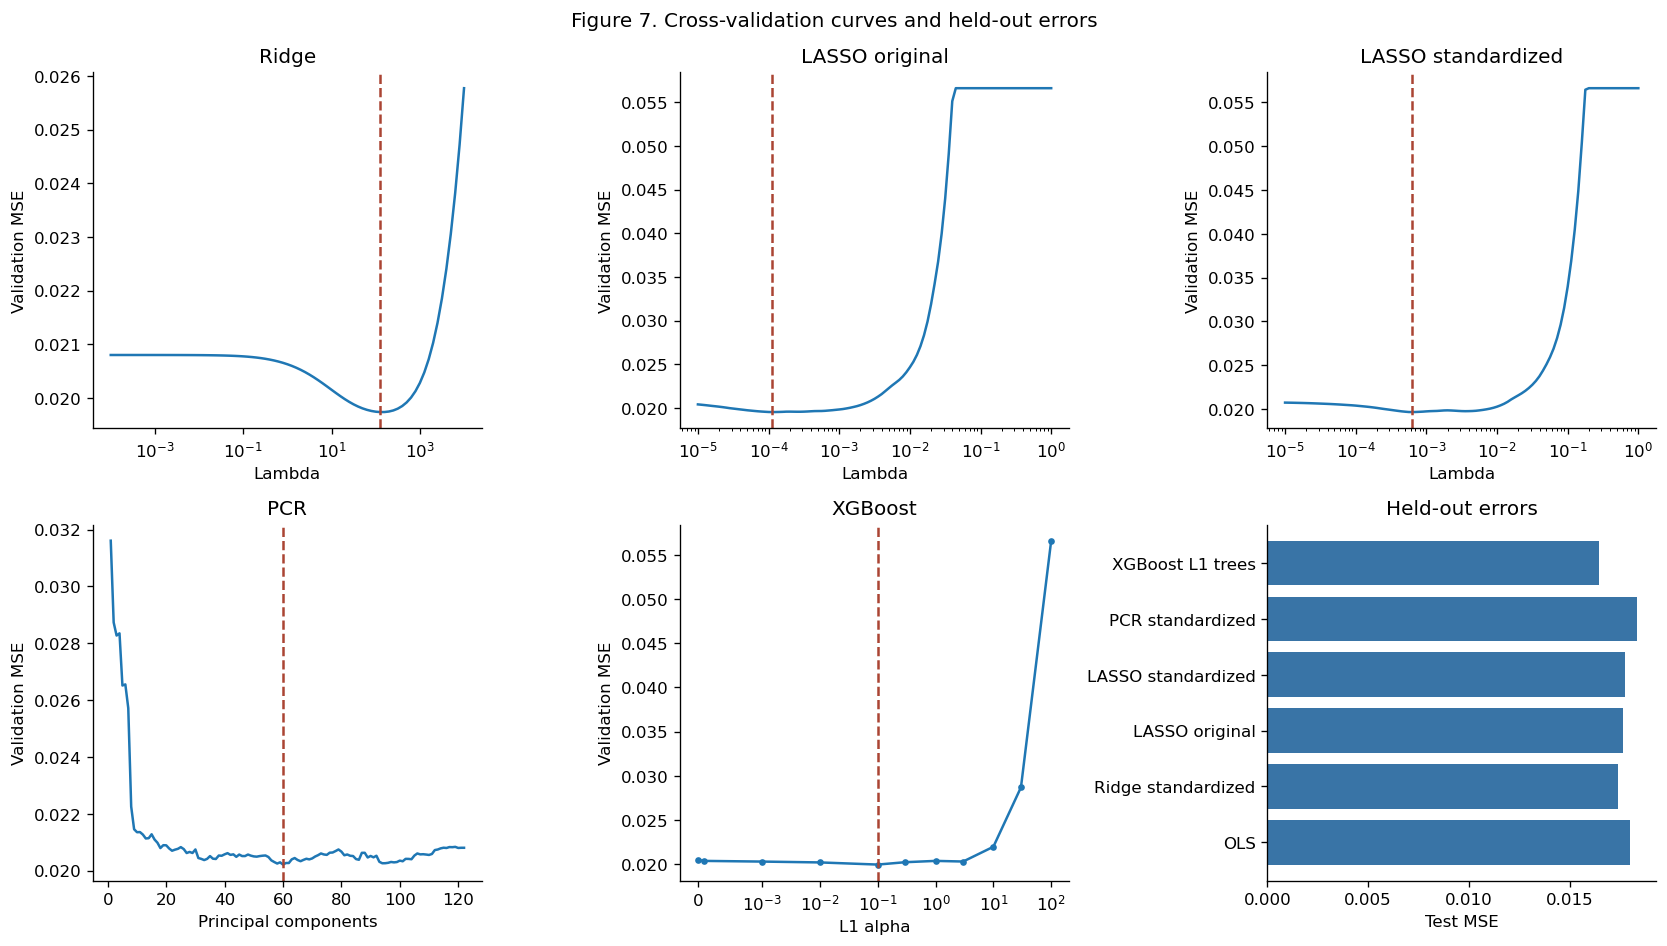

lowest_validation_mse      LASSO original
lowest_test_mse          XGBoost L1 trees
convergence_warnings                    0
dtype: object

In [16]:
comparison = pd.DataFrame(regression_results).set_index("model")
display(comparison.sort_values("cv_mse"))
comparison.to_csv(results_dir / "regression_comparison.csv")
test_predictions.to_csv(results_dir / "regression_test_predictions.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes[0, 0].semilogx(ridge_cv["lambda"], ridge_cv.cv_mse)
axes[0, 0].axvline(ridge_lambda, linestyle="--", color="#aa4433")
axes[0, 0].set(title="Ridge", xlabel="Lambda", ylabel="Validation MSE")
for ax, label in zip(axes[0, 1:], ["LASSO original", "LASSO standardized"]):
    table = lasso_tables[label]
    ax.semilogx(table["lambda"], table.cv_mse)
    ax.axvline(models[label].named_steps["model"].alpha, linestyle="--", color="#aa4433")
    ax.set(title=label, xlabel="Lambda", ylabel="Validation MSE")
axes[1, 0].plot(pcr_cv.M, pcr_cv.cv_mse)
axes[1, 0].axvline(best_M, linestyle="--", color="#aa4433")
axes[1, 0].set(title="PCR", xlabel="Principal components", ylabel="Validation MSE")
axes[1, 1].plot(xgb_cv.alpha, xgb_cv.cv_mse, marker=".")
axes[1, 1].set_xscale("symlog", linthresh=.001)
axes[1, 1].axvline(xgb_alpha, linestyle="--", color="#aa4433")
axes[1, 1].set(title="XGBoost", xlabel="L1 alpha", ylabel="Validation MSE")
axes[1, 2].barh(comparison.index, comparison.test_mse, color="#3974a6")
axes[1, 2].set(xlabel="Test MSE", title="Held-out errors")
fig.suptitle("Figure 7. Cross-validation curves and held-out errors")
fig.tight_layout()
plt.show()
coefficient_table = pd.DataFrame(index=X.columns)
for name in ["OLS", "Ridge standardized", "LASSO original", "LASSO standardized"]:
    model = models[name]
    coefficient_table[name] = model.named_steps["model"].coef_
coefficient_table.to_csv(results_dir / "regression_coefficients.csv", index_label="feature")
summary = {"tree_one_se_alpha": float(one_se_row.alpha),
           "tree_compact_alpha": float(compact_row.alpha),
           "tree_full_leaves": int(full_tree.get_n_leaves()), "tree_compact_leaves": int(pruned_tree.get_n_leaves()),
           "ridge_lambda": ridge_lambda,
           "lasso_original_lambda": float(models["LASSO original"].named_steps["model"].alpha),
           "lasso_standardized_lambda": float(models["LASSO standardized"].named_steps["model"].alpha),
           "lasso_original_selected": selected_lasso["LASSO original"].feature.tolist(),
           "lasso_standardized_selected": selected_lasso["LASSO standardized"].feature.tolist(),
           "pcr_M": best_M, "xgboost_alpha": xgb_alpha,
           "top_cv_features": top_features, "convergence_warnings": convergence_messages}
(results_dir / "selected_models.json").write_text(json.dumps(summary, indent=2) + "\n")
display(pd.Series({"lowest_validation_mse": comparison.cv_mse.idxmin(),
                   "lowest_test_mse": comparison.test_mse.idxmin(),
                   "convergence_warnings": len(convergence_messages)}))

## References

1. Czerniak, J. (2003). [Acute Inflammations](https://doi.org/10.24432/C5V59S).
   UCI Machine Learning Repository, CC BY 4.0.
2. Redmond, M. (2002). [Communities and Crime](https://doi.org/10.24432/C53W3X).
   UCI Machine Learning Repository, CC BY 4.0.
3. scikit-learn documentation: [cost-complexity pruning](https://scikit-learn.org/1.5/modules/tree.html#minimal-cost-complexity-pruning),
   [LASSO paths](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.lasso_path.html),
   [ridge regression](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.Ridge.html),
   and [principal component regression](https://scikit-learn.org/1.5/auto_examples/cross_decomposition/plot_pcr_vs_pls.html).
4. XGBoost documentation: [tree-booster parameters](https://xgboost.readthedocs.io/en/stable/parameter.html#parameters-for-tree-booster).